# Lernfall 4:

**Wissenslücken:** 
Gruppe 1: Jakob Cleve, Badder Tinawi, Caner Eker, Hlib Astashev 

- Wie erstellt man Grafiken in Python, und welche Bibliotheken gibt es dafür? 
Dash, Matplotlib, Plotly 
- Wie laden wir die Kursdaten des DAX mit yfinance? 
- Wie berechnen wir mit pandas die täglichen Renditen und die Volatilität? 
- Wie ordnet man fünf Grafiken (Aktie vs. DAX) in einer gemeinsamen Abbildung an? 
- Wie stellen wir Rendite und Risiko in einem Streudiagramm dar, und wie setzt man das in Python um? 
 Risiko und Rendite 
- Warum muss der DAX im selben Zeitraum wie die Aktie verglichen werden? 
- Was bedeutet Risiko bei Aktien, und mit welchen Kennzahlen misst man es? 
- Was ist die Volatilität, und wie berechnet man sie? 
- Was sagt die Sharpe Ratio aus? 
- Was ist der maximale Drawdown? 
- <Woran erkennen wir, ob sich das Risiko gegenüber dem DAX gelohnt hat? 

## 0. Einstellungen


In [1]:
PORTFOLIO = {
    "Allianz SE":               ("ALV.DE",  "2021-09-30"),
    "SAP SE":                   ("SAP.DE",  "2022-03-15"),
    "Infineon Technologies AG": ("IFX.DE",  "2022-06-01"),
    "Deutsche Telekom AG":      ("DTE.DE",  "2023-01-03"),
    "Münchener Rück AG":        ("MUV2.DE", "2023-09-29"),
}
BENCHMARK_NAME, BENCHMARK_TICKER = "DAX", "^GDAXI"
END_DATE = "2026-09-23"

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

tickers = [t for t, _ in PORTFOLIO.values()] + [BENCHMARK_TICKER]
start = min(d for _, d in PORTFOLIO.values())
end_excl = (pd.Timestamp(END_DATE) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")  # yfinance: Enddatum exklusiv

raw = yf.download(tickers, start=start, end=end_excl, auto_adjust=False, progress=False)
prices = raw["Adj Close"].ffill()

def holding_period(series, buy_date):
    """Kurse ab dem ersten Handelstag am oder nach dem Kaufdatum."""
    return series.loc[pd.Timestamp(buy_date):].dropna()

prices.tail()

Ticker,ALV.DE,DTE.DE,IFX.DE,MUV2.DE,SAP.DE,^GDAXI
Date,,,,,,
2026-09-17,451.100006,28.299999,54.400002,510.600006,188.000000,25716.710938
2026-09-18,443.299988,27.110001,55.860001,505.799988,183.119995,25304.060547
2026-09-21,445.100006,27.290001,58.290001,508.799988,182.860001,25575.009766
2026-09-22,430.200012,27.110001,60.130001,501.799988,182.320007,25578.849609
2026-09-23,413.100006,26.830000,58.570000,502.600006,186.460007,25410.630859


## 1. Jede Aktie gegen den DAX im selben Zeitraum

Aktie und DAX starten jeweils am Kaufdatum dieser Aktie bei 100.

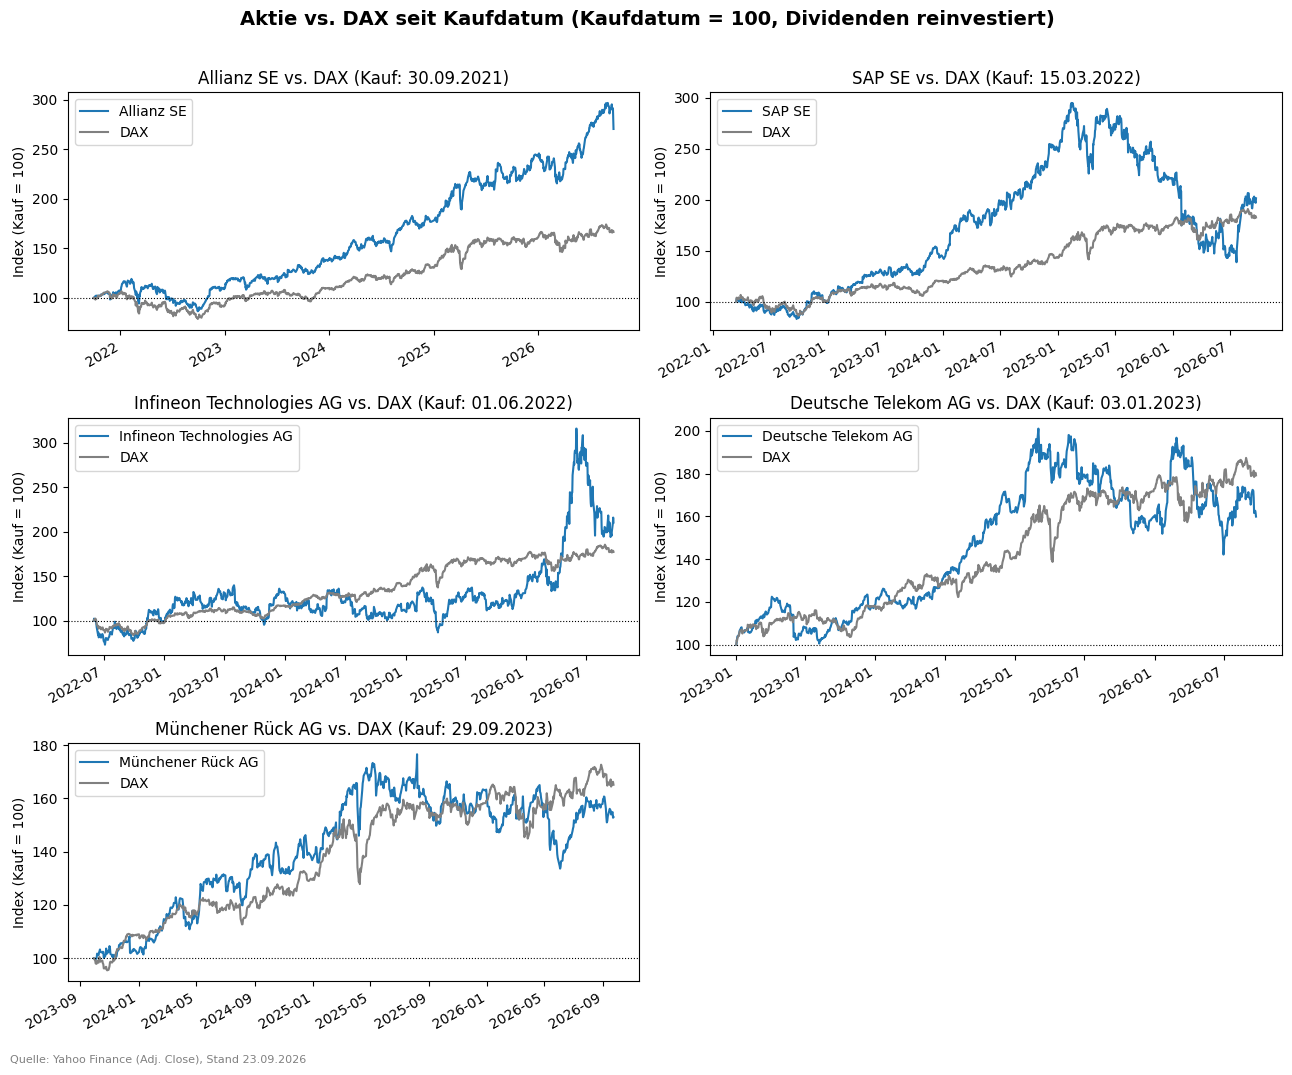

In [5]:
n = len(PORTFOLIO)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.6 * nrows), sharey=False)
axes = axes.flatten()

for ax, (name, (ticker, buy)) in zip(axes, PORTFOLIO.items()):
    stock = holding_period(prices[ticker], buy)
    dax = holding_period(prices[BENCHMARK_TICKER], buy)
    (stock / stock.iloc[0] * 100).plot(ax=ax, label=name, lw=1.5)
    (dax / dax.iloc[0] * 100).plot(ax=ax, label=BENCHMARK_NAME, color="grey", lw=1.5)
    ax.axhline(100, color="black", ls=":", lw=0.8)
    ax.set_title(f"{name} vs. {BENCHMARK_NAME} (Kauf: {pd.Timestamp(buy):%d.%m.%Y})")
    ax.set_ylabel("Index (Kauf = 100)")
    ax.set_xlabel("")
    ax.legend(loc="upper left")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle("Aktie vs. DAX seit Kaufdatum (Kaufdatum = 100, Dividenden reinvestiert)", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, f"Quelle: Yahoo Finance (Adj. Close), Stand {pd.Timestamp(END_DATE):%d.%m.%Y}", fontsize=8, color="grey")
fig.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()

## 2. Risiko messen

**Volatilität:** Sie misst, wie stark der Kurs von Tag zu Tag schwankt. Man nimmt die täglichen Renditen, berechnet deren Standardabweichung und rechnet sie aufs Jahr hoch (× √252 Handelstage). Eine Volatilität von 30 % heißt grob: Ein Jahr mit ±30 % Abweichung vom Durchschnitt ist ganz normal.

**Maximaler Verlust (Max. Drawdown):** Der größte Absturz vom bisherigen Höchststand bis zum Tiefpunkt. Das ist genau das „steil bergab“, das Frau Keller meint: So viel hätte sie im schlimmsten Moment auf dem Papier verloren.

In [6]:
def cagr(s):
    years = (s.index[-1] - s.index[0]).days / 365.25
    return (s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1

def volatility(s):
    return s.pct_change().dropna().std() * np.sqrt(252)

def max_drawdown(s):
    return (s / s.cummax() - 1).min()

rows = []
for name, (ticker, buy) in PORTFOLIO.items():
    stock = holding_period(prices[ticker], buy)
    dax = holding_period(prices[BENCHMARK_TICKER], buy)
    rows.append({
        "Aktie": name,
        "CAGR Aktie": cagr(stock), "CAGR DAX": cagr(dax),
        "Vola Aktie": volatility(stock), "Vola DAX": volatility(dax),
        "MaxDD Aktie": max_drawdown(stock), "MaxDD DAX": max_drawdown(dax),
    })
res = pd.DataFrame(rows).set_index("Aktie")

# DAX als eigener Punkt: über den gesamten Zeitraum ab dem frühesten Kaufdatum
dax_all = holding_period(prices[BENCHMARK_TICKER], start)
dax_row = {"CAGR": cagr(dax_all), "Vola": volatility(dax_all), "MaxDD": max_drawdown(dax_all)}

overview = pd.DataFrame({
    "CAGR": res["CAGR Aktie"], "Volatilität": res["Vola Aktie"], "Max. Drawdown": res["MaxDD Aktie"],
})
overview.loc[f"{BENCHMARK_NAME} (ab {pd.Timestamp(start):%d.%m.%Y})"] = [dax_row["CAGR"], dax_row["Vola"], dax_row["MaxDD"]]
overview.style.format("{:.1%}")

,CAGR,Volatilität,Max. Drawdown
Aktie,,,
Allianz SE,22.1%,19.3%,-27.5%
SAP SE,16.7%,29.1%,-53.0%
Infineon Technologies AG,18.8%,41.8%,-38.6%
Deutsche Telekom AG,13.4%,20.6%,-29.3%
Münchener Rück AG,15.3%,21.3%,-24.3%
DAX (ab 30.09.2021),10.8%,17.0%,-26.4%


## 3. Rendite vs. Risiko

Oben links = viel Rendite bei wenig Schwankung (gut), unten rechts = wenig Rendite bei viel Schwankung (schlecht).

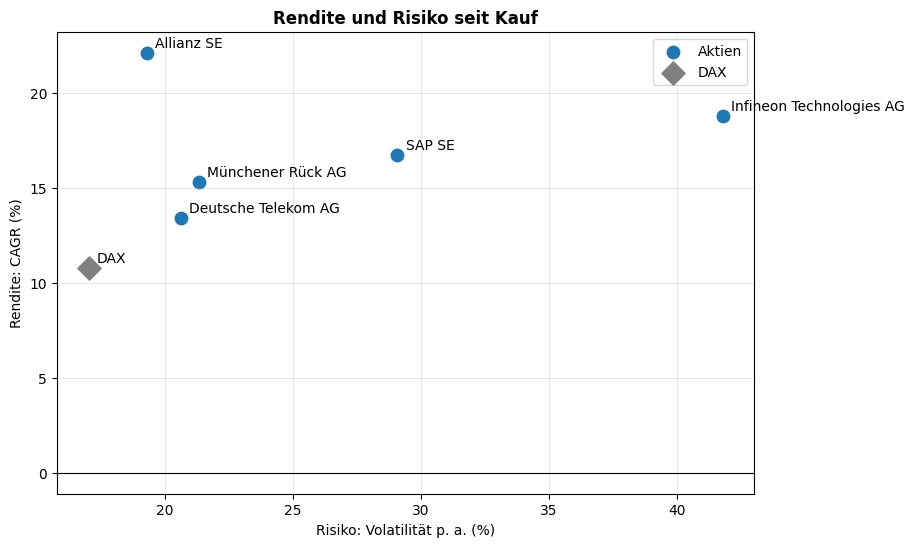

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(res["Vola Aktie"] * 100, res["CAGR Aktie"] * 100, s=80, label="Aktien")
for name, r in res.iterrows():
    ax.annotate(name, (r["Vola Aktie"] * 100, r["CAGR Aktie"] * 100), xytext=(6, 4), textcoords="offset points")
ax.scatter(dax_row["Vola"] * 100, dax_row["CAGR"] * 100, s=140, marker="D", color="grey", label=BENCHMARK_NAME)
ax.annotate(BENCHMARK_NAME, (dax_row["Vola"] * 100, dax_row["CAGR"] * 100), xytext=(6, 4), textcoords="offset points")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Risiko: Volatilität p. a. (%)")
ax.set_ylabel("Rendite: CAGR (%)")
ax.set_title("Rendite und Risiko seit Kauf", fontweight="bold")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 4. Hat sich das Risiko gelohnt?

Vergleich jeder Aktie mit dem DAX **im selben Zeitraum**:

In [8]:
def verdict(r):
    if r["CAGR Aktie"] > r["CAGR DAX"]:
        if r["Vola Aktie"] > r["Vola DAX"]:
            return "Mehr Risiko, aber auch mehr Rendite → Risiko hat sich gelohnt"
        return "Mehr Rendite bei weniger Risiko → klar besser als DAX"
    if r["Vola Aktie"] > r["Vola DAX"]:
        return "Mehr Risiko, weniger Rendite → lieber DAX"
    return "Weniger Rendite, weniger Risiko → DAX wäre rentabler gewesen"

res["Ergebnis"] = res.apply(verdict, axis=1)
res["Vorsprung ggü. DAX (CAGR)"] = res["CAGR Aktie"] - res["CAGR DAX"]
display(res[["CAGR Aktie", "CAGR DAX", "Vorsprung ggü. DAX (CAGR)", "Vola Aktie", "Vola DAX", "Ergebnis"]]
        .style.format({c: "{:.1%}" for c in res.columns if c != "Ergebnis"}))

replace = res.index[res["CAGR Aktie"] < res["CAGR DAX"]].tolist()
print("Im Nachhinein lieber durch den DAX ersetzt:", ", ".join(replace) if replace else "keine")

,CAGR Aktie,CAGR DAX,Vorsprung ggü. DAX (CAGR),Vola Aktie,Vola DAX,Ergebnis
Aktie,,,,,,
Allianz SE,22.1%,10.8%,11.3%,19.3%,17.0%,"Mehr Risiko, aber auch mehr Rendite → Risiko hat sich gelohnt"
SAP SE,16.7%,14.2%,2.5%,29.1%,16.1%,"Mehr Risiko, aber auch mehr Rendite → Risiko hat sich gelohnt"
Infineon Technologies AG,18.8%,14.2%,4.6%,41.8%,15.8%,"Mehr Risiko, aber auch mehr Rendite → Risiko hat sich gelohnt"
Deutsche Telekom AG,13.4%,17.0%,-3.5%,20.6%,15.0%,"Mehr Risiko, weniger Rendite → lieber DAX"
Münchener Rück AG,15.3%,18.3%,-3.0%,21.3%,15.3%,"Mehr Risiko, weniger Rendite → lieber DAX"


Im Nachhinein lieber durch den DAX ersetzt: Deutsche Telekom AG, Münchener Rück AG


### Antwort an Frau Keller

*(nach dem Ausführen anhand der Tabelle oben anpassen)*

- **Stimmt die Aussage des Nachbarn?** Nur teilweise. Aktien mit höherer Rendite als der DAX haben sich trotz der Schwankungen gelohnt. Bei den Aktien aus der Liste „lieber durch den DAX ersetzt“ wäre sie mit dem DAX besser gefahren, oft sogar mit weniger Aufregung.

